# 08-闭环控制与PID


## 1. 本篇范围与核心问题

前两篇通过运动学正解与逆解，建立了关节位置和末端位姿之间的关系。逆解给出目标关节角后，还需要让真实电机带动机械臂到达目标，并在负载变化或受到干扰时维持位置。

本篇依据两份课程 PPT 整理：

- `具身智能-控制论.pptx`，全部 **16 页**。
- `具身智能-PID.pptx`，全部 **14 页**。

课程先讨论指令与实际结果的差异，比较开环与闭环控制，再介绍 PID 如何使用误差的当前大小、累计值和变化趋势。

两份 PPT 以概念、生活类比和无人机高度控制为主，没有提供机械臂 PID 程序、采样周期、具体增益或调参流程。本篇先讲清课件中的控制逻辑，不将示意公式写成已经验证的实机方案。


## 2. 指令与实际结果之间的差异

控制论课件从一个任务出发：让机械臂第一个关节，也就是腰部，旋转 `30°`。

计算出目标角度，并不代表电机能够瞬间到位。实际运动需要时间，电机受到驱动、惯性、摩擦与负载影响。

课件提出的几个不确定因素包括：

| 因素 | 对原有指令的影响 |
|---|---|
| 电源波动 | 电压不稳定或电池电量下降，可能改变驱动表现 |
| 负载变化 | 抓起重物后，需要的驱动力矩发生变化 |
| 系统老化 | 齿轮磨损、润滑与摩擦变化，使原有参数不再准确 |
| 环境干扰 | 外力碰撞或推动，可能使关节偏离预期位置 |

因此，同一条驱动指令在不同条件下，可能产生不同的最终角度。这是本节引入控制与反馈的原因。

> **补充说明：**课件提出“电压与转速是否有关”，但没有推导电机模型。电压、转速、负载和运动时间之间存在联系，不能把它们简化成任意情况下都成立的“某个电压就对应某个角度”。


## 3. 开环控制：不根据输出修正

开环控制（Open-Loop Control）的信息流从目标、控制器到执行系统和输出，控制器不使用这个受控输出的测量结果来修正指令。

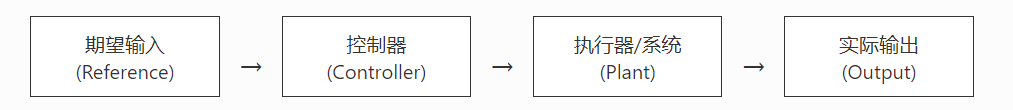

例如，根据预先估计的规律，给电机施加一定驱动、持续一定时间，然后认为关节已到达 `30°`。

课件用“相信模型和预设指令”的类比解释这种方式：只要实际系统与预期一致，就可以按预先设计的动作运行；一旦条件变化，控制器没有输出反馈来识别偏差。

> **补充说明：**开环的判断针对当前受控量。一个系统可能具有其他传感器，但如果没有把关节角度的测量用于角度控制，它仍然不构成这个受控量的闭环。


## 4. 课件中的开环例子

控制论第 5 页的表格使用生活中的定时操作作类比。

| 系统 | 课件描述的工作方式 | 没有直接反馈的信息 |
|---|---|---|
| 烤面包机 | 按设定时间加热 `3 分钟` | 面包是否达到期望烘烤程度 |
| 老式洗衣机 | 执行标准洗涤 `15 分钟` | 衣物是否已经洗净 |
| 定时浇水器 | 每天早上 `8 点`浇水 `30 分钟` | 土壤是否已经足够湿润、近期是否下雨 |
| 机械臂的最初设想 | 给电机持续 `0.5 秒`的 `5 V` 电压 | 最终是否真正转到 `30°` |

这些例子的共同点是按照时间或预定规则执行，没有围绕最终效果持续修正。

> **课件例子的边界：**上述说明针对 PPT 描述的定时模式，不代表所有同类产品都是开环。`5 V、0.5 秒、30°` 也是课程中的假设例子，并非某个机械臂电机的实测对应关系。


## 5. 开环控制面对的三类变化

### 5.1 模型不准与参数漂移

控制论第 6 页举例：原来能够产生 `30°` 运动的指令，因老化或摩擦变化，现在可能只能产生 `28°`。

这种模型参数随时间发生的变化称为**参数漂移**。如果没有角度反馈，控制器无法仅凭原指令知道还差 `2°`。

### 5.2 外部干扰

课件把未被模型描述、却会影响输出的外部输入称为干扰。例如，运动过程中有人推动机械臂，使它偏离原有运动状态。

开环控制没有根据偏离量进行补偿的环节。

> **补充说明：**PPT 将干扰影响描述为会永久留在结果中，这取决于系统自身动态。更一般的结论是：开环不会依据输出误差主动消除干扰，不能据此断定每一次干扰都必然留下永久偏差。

### 5.3 负载变化

课件第 8 页继续比较：空载时达到 `30°`，拿起水杯后，相同指令可能只达到 `25°`。负载带来的额外阻力使预设动作不再适合当前条件。

第 9 页总结了开环的实现优势：结构简单、成本较低，不需要为这一控制目标增加反馈测量。代价是结果较依赖模型和工作条件，遇到未知变化时缺少纠偏手段。

> **课件表述修正：**PPT 写“开环固有稳定，不会产生振荡”。开环结构本身不能保证稳定，被控对象仍可能有振荡或不稳定动态。这里可以理解为没有引入反馈环路所带来的额外稳定性问题，不能作为“开环一定稳定”的结论。


## 6. 反馈、误差与闭环控制

闭环控制（Closed-Loop Control）增加了反馈：用传感器测量输出，将测量结果与目标比较，再根据误差调整驱动。

课件给出的核心关系是：

$$
\mathrm{Error}=\mathrm{Setpoint}-\mathrm{Actual\ Value}
$$

本篇使用 `r(t)` 表示目标、`y_m(t)` 表示传感器测量值，误差写为：

$$
e(t)=r(t)-y_m(t)
$$

例如，目标角为 `30°`，测量角为 `28°`，则 `e = 2°`；测量角为 `35°` 时，误差为 `-5°`。误差的大小和正负共同为控制器提供调整依据。

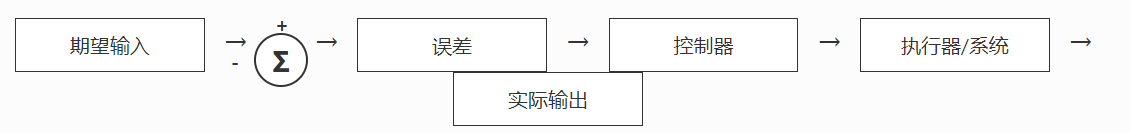

> **读图说明：**原图的回路线没有完整画出。应按第 10—11 页正文理解：从执行系统输出取得测量，再回到前端比较点的负号输入，形成反馈；不能将图中“实际输出”文字框的位置当作输出直接来自控制器。

闭环不断重复“测量、比较、调整”，目标是使实际表现接近期望结果。

> **补充说明：**传感器给出的是测量结果，可能存在误差、噪声或延迟。控制器通常直接减小的是测量误差，测量值到达目标不等于真实状态绝对无误差。驱动的正方向还必须与误差定义配合，保证调整动作是在纠偏。


## 7. 用驾驶过程理解闭环

控制论第 12 页以人开车保持车道为例。

| 控制环节 | 驾驶例子中的对应物 |
|---|---|
| 期望输入 | 道路中线或希望保持的行驶位置 |
| 实际输出 | 汽车当前位置 |
| 传感器 | 眼睛 |
| 控制器 | 大脑 |
| 执行器 | 手与方向盘 |
| 误差与修正 | 观察偏离程度，再调整方向 |

驾驶者持续观察位置偏差，偏左时向相应方向修正，再看修正后的结果。每一次转动方向盘都会影响后续观察到的位置。

课件还列举调节洗澡水温和现代空调恒温系统。它们同样利用测量或感知到的结果，调整后续操作。

这个例子强调持续反馈的过程。具体如何选择修正幅度，则属于控制器设计的问题。


## 8. 闭环的优势与能力范围

控制论第 13 页将反馈的作用对应到前面的三类困难。

| 情况 | 闭环的应对方式 |
|---|---|
| 模型不准、设备老化 | 发现测量角仍为 `28°`，根据相对 `30°` 的偏差继续调整 |
| 受到外力干扰 | 测量偏离目标后，输出相应修正 |
| 抓起更重物体 | 根据新的实际结果调整驱动，补偿负载带来的影响 |

控制器因此能够在一定范围内补偿模型误差和外界变化，不必只依赖预先估计的指令。

> **课件表述的边界：**PPT 用“只要没到目标就继续努力”说明反馈机制。能否到位还受电机力矩、驱动限幅、机械限位、传感器与控制器设计影响。反馈不能让能力不足的执行器完成超出其范围的任务，也不能保证任何干扰都能即时检测和完全消除。


## 9. 闭环的新问题：超调与振荡

控制论第 14 页指出：反馈带来纠偏能力，也使稳定性成为控制器设计的重要问题。

如果控制器反应过强，也就是增益过高，或者测量与动作之间存在延迟，修正动作可能超过需要。

| 现象 | 课件例子 | 含义 |
|---|---|---|
| 超调（Overshoot） | 目标 `30°`，实际冲到 `35°` | 响应越过目标 |
| 振荡（Oscillation） | 在目标附近反复摆动 | 修正来回发生，可能难以稳定 |

这引出后续问题：如何既较快响应，又减少残余误差，同时避免过度修正？PID 就是在误差基础上组织控制输出的一种经典方法。

> **补充说明：**出现一次超调不必然表示系统不稳定，衰减振荡也可能最终收敛。课件在这里列举的是需要关注的响应表现，稳定性还要结合长期行为判断。


## 10. 开环与闭环的核心对比

控制论第 3、9、15 页的比较可整理为：

| 特性 | 开环控制 | 闭环控制 |
|---|---|---|
| 控制依据 | 目标、模型或预设规则 | 目标与输出反馈形成的误差 |
| 信息结构 | 对该受控量单向执行 | 输出测量返回前端参与修正 |
| 关键要素 | 预设指令及执行系统 | 在执行系统之外增加反馈、比较与修正 |
| 实现特点 | 通常结构较简单、成本较低 | 需要测量与控制设计，复杂度增加 |
| 面对变化 | 缺少基于结果的主动纠偏 | 合理设计时可补偿一定的扰动与参数变化 |
| 稳定性 | 仍取决于对象与输入 | 还需考虑反馈增益和延迟等影响 |
| 课程类比 | 定时烤面包、定时洗衣 | 空调恒温、驾驶保持车道 |

表中的性能比较以课件讨论的应用为背景，不把“开环精度差、闭环一定精准”作为不受条件限制的定律。

控制论第 16 页引出 PID，下一份 PPT 继续展开如何使用误差。


## 11. 从开关控制到 PID

PID 课件先回顾 `误差 = 目标值 − 实际值`，然后用室温控制说明只按误差正负切换输出的局限。

### 11.1 Bang-Bang 开关控制

课件设定目标温度为 `26°C`：

- 低于 `26°C`，暖气开到最大。
- 高于 `26°C`，暖气关闭。

这种控制器围绕阈值切换两个输出状态，称为 Bang-Bang 控制，也就是开关控制。在课件的示意中，热惯性等因素使温度上下波动。

> **课件表述的边界：**“永远无法稳定”是对这个例子中波动的强调。开关控制是否满足要求，取决于系统动态与允许温度范围，不能据此判断所有开关控制都不可用。它使用温度反馈，所以本例仍属于闭环。

### 11.2 PID 使用三类误差信息

| 部分 | 英文 | 课件中的时间类比 | 直接依据 |
|---|---|---|---|
| P：比例 | Proportional | 现在 | 当前误差多大 |
| I：积分 | Integral | 过去 | 误差在时间上的累计 |
| D：微分 | Derivative | 未来趋势 | 误差变化得有多快 |

> **补充说明：**D 从当前变化趋势提供修正，并不真正知道未来状态。PID 也不要求每次都同时使用三项，后面还会比较 P、PI、PD 等组合。


## 12. 无人机高度控制的例子

PID 第 5 页设置一个场景：无人机从 `100 m` 高处出发，希望在 `50 m` 平台高度平稳悬停。

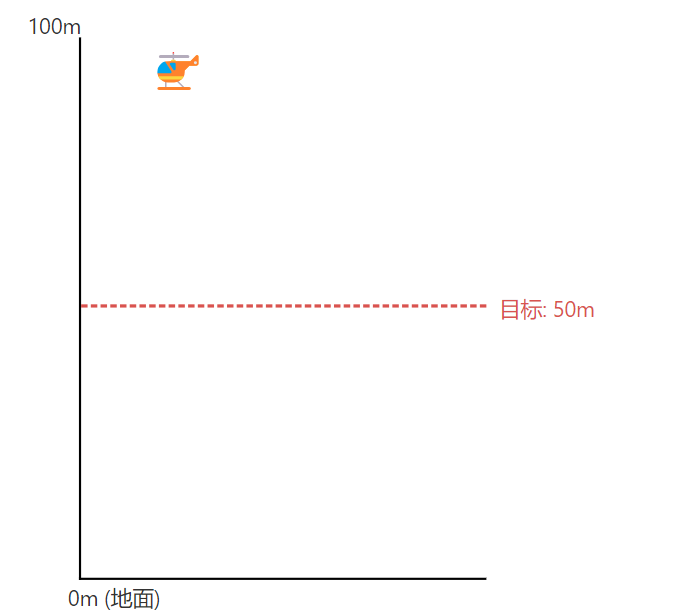

设测量高度为 `h(t)`，目标高度为 `50 m`，则：

$$
e(t)=50-h(t)
$$

| 当前高度 | 误差 | 对应关系 |
|---|---|---|
| `100 m` | `−50 m` | 当前高于目标 |
| `60 m` | `−10 m` | 仍高于目标，但距离缩小 |
| `50 m` | `0 m` | 高度与目标相同 |
| `48 m` | `+2 m` | 当前低于目标 |

课件将输出描述为通过螺旋桨转速调节升力。后面的“减小输出”“增加输出”都是围绕这一控制方向展开。

> **模型补充说明：**实际螺旋桨转速不能按正负误差直接取任意负值，转速到升力也不是这里给出的简单比例公式。课件用简化输出解释 PID：负误差代表应减少升力，正误差代表应增加升力。零误差本身既不代表速度为零，也不代表已经达到稳定悬停。


## 13. P：按当前误差产生输出

PID 第 6 页给出比例控制：

$$
u_P(t)=K_p e(t)
$$

`Kₚ` 为比例增益。增益与符号方向固定时，当前误差越大，比例项的幅度越大；误差变小，比例项也变小。

在无人机例子中：

- 高度 `100 m`，误差为 `−50 m`，课件用较大的减小升力动作说明大误差时的反应。
- 高度 `60 m`，误差为 `−10 m`，比例修正减弱。
- 到达 `50 m`，比例项为零。

> **补充说明：**到达目标时 `P=0` 只说明比例项不再提供修正，不能解释为无人机自动停止下降。物体可能仍有速度，需要其他动力学因素或控制项配合。

### 13.1 为什么课件中的 P 会留下稳态误差

第 7 页强调，悬停需要持续升力抵消重力。如果全部升力都由 `Kₚe` 提供，而没有其他基础输出，零误差就意味着比例输出为零，无法支撑悬停。

因此，课件用无人机停在 `48 m` 作示意：残余的 `2 m` 误差使比例项提供一定输出，用来抵消重力。

这种稳定下来后仍存在的偏差称为**稳态误差**。`48 m` 是说明机制的假设值，PPT 没有给出质量和增益，无法据此计算实际平衡高度。

> **条件补充说明：**“P 一定有稳态误差”过于绝对。是否存在稳态误差取决于对象、输入、扰动与基础输出等因素。本例是在“需要持续输出，但只用比例误差提供它”的假设下说明问题；纯 P 的动态响应也不保证一定能稳定到某个高度。


## 14. I：累计误差，补足持续输出

PID 第 8 页给出积分项：

$$
u_I(t)=K_i\int_0^t e(\tau)\,\mathrm d\tau
$$

当误差持续存在时，积分累计值会变化，积分项因此能够逐渐补足只靠 P 难以维持的输出。

课件继续使用无人机在 `48 m`、存在 `2 m` 偏差的例子。如果偏差保持不变，累计时间越长，积分项就越大，促使系统继续向目标修正。

> **补充说明：**积分同时考虑误差大小和持续时间，不只是记下“发生过几次误差”。持续 `2 m` 误差经过 `1 s` 的积分为 `2 m·s`，经过 `2 s` 为 `4 m·s`，还需要乘 `Kᵢ` 才得到积分控制输出。

到达目标后，当前误差为零，积分累计值可以保持原有数值。因此，零误差时积分项仍然能够提供非零输出，课件用它解释持续抵消重力的作用。

### 14.1 积分的优势与限制

第 9 页强调积分能够消除稳态误差，同时指出累计需要时间，可能增加超调。

> **适用条件：**积分消除某些持续偏差的结论以闭环稳定、目标可达、执行器能力足够等条件为前提。加入 I 并不自动保证任何误差都能归零。

### 14.2 积分饱和与过度累计

课件使用**积分饱和（Integral Windup）**解释过大的历史累计：误差长期存在，积分项不断增加；接近目标后，过大的累计还在推动系统，可能造成明显超调。

> **机制补充说明：**典型 windup 发生在执行器已经达到输出上限等受限情况下，积分仍持续累计。即使目标已经到达，积分也不会因为当前误差变成零而立刻清空。PPT 没有提供抗积分饱和的实现代码，这里先保留机制说明。


## 15. D：根据误差变化提供阻尼

PID 第 10 页给出微分项：

$$
u_D(t)=K_d\frac{\mathrm de(t)}{\mathrm dt}
$$

它关注误差的变化速度。在课件的直观解释中，系统快速接近目标时，D 提供“提前刹车”的效果，帮助减少超调与振荡。

### 15.1 无人机下降时的符号

目标高度固定时：

$$
\frac{\mathrm de}{\mathrm dt}=-\frac{\mathrm dh}{\mathrm dt}
$$

无人机从上方下降时，高度变化率为负，所以误差变化率为正。在 `K_d>0` 且增加输出代表增加升力的约定下，D 项提供正向升力修正，抑制下降速度。

> **课件措辞说明：**PPT 写“误差正以极快速度减小”。这里减小的是距离目标的偏差幅度；按照 `e=50−h` 的带符号定义，误差实际由较大的负值向零增加。读公式时需要保留这个符号区别。

D 的阻尼作用与测量变化有关，不能只看当前是否已经超过目标。

### 15.2 微分对噪声敏感

第 11 页指出，传感器数值如果快速小幅跳动，微分会把这种变化放大为控制信号的抖动。

课件因此说明 D 部分通常需要对信号进行滤波。滤波可以降低噪声影响，但具体实现和参数没有在 PPT 中展开。

> **补充说明：**D 有助于减轻某些系统的超调和振荡，但效果仍取决于模型和参数。将它称为“预测未来”是趋势类比，不代表加入 D 就能保证响应稳定。


## 16. PID：三项输出相加

PID 第 12—13 页将三项合在一起：P 根据当前误差修正，I 根据累计误差补偿，D 根据变化趋势提供阻尼。

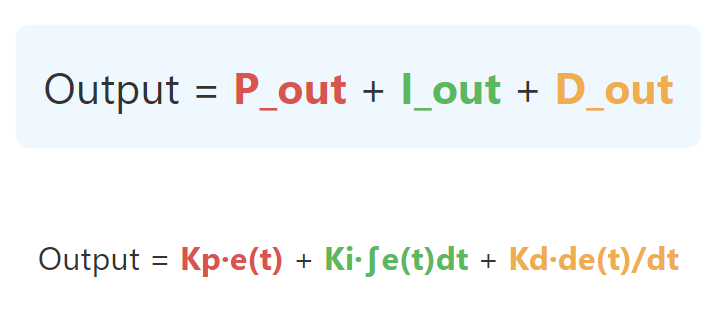

使用本篇符号，连续时间的并联形式为：

$$
u(t)=K_p e(t)+K_i\int_0^t e(\tau)\,\mathrm d\tau
+K_d\frac{\mathrm de(t)}{\mathrm dt}
$$

| 部分 | 主要作用 | 本课强调的问题 |
|---|---|---|
| P | 对当前误差提供直接响应 | 单独使用可能留下偏差，反应过强可能增加超调 |
| I | 累计误差，提供持续修正 | 累计过度、输出受限时可能发生 windup |
| D | 根据变化率抑制快速变化 | 对测量噪声敏感 |

三项作用于同一个输出，参数选择会相互影响，不能把课件中的三种性格类比当成彼此独立的性能保证。

### 16.1 数字控制中的时间间隔

> **补充说明：**机械臂控制程序通常按采样时刻更新。为了对应上面的积分和微分，在简单离散近似中，需要考虑实际时间间隔 `Δt`：

$$
S_k=S_{k-1}+e_k\Delta t,\qquad
D_k\approx\frac{e_k-e_{k-1}}{\Delta t}
$$

这里 `Sₖ` 是误差积分的累计近似，`Dₖ` 是误差变化率的近似，还需要分别乘 `Kᵢ、K_d` 才形成输出项。

采样间隔改变后，忽略时间尺度会改变积分和微分的含义。这只是连续公式的对应说明，不是课件未提供的完整数字 PID 实现。


## 17. P、PI、PD 与 PID 的组合

PID 第 14 页比较四种组合。

| 组合 | 课件强调的特点 | 阅读时需要保留的条件 |
|---|---|---|
| P | 简单、反应直接，可能存在稳态误差 | 是否有偏差、能否稳定取决于对象与工作条件 |
| PI | 加入积分以消除持续偏差，但可能增加超调或延长稳定时间 | 需要关注积分累计和输出能力 |
| PD | 利用微分改善阻尼、减少超调 | 不具备积分累计补偿，对噪声敏感 |
| PID | 综合三项，兼顾响应、精度与平稳性 | 仍要匹配系统动态与参数，不能自动保证最佳效果 |

PPT 将 PI 描述为工业中常用的组合，将 PD 用于快速稳定的场景。这些是应用倾向，不表示所有机械臂都必须选择同一个组合。

课件最后用“稳、准、快的平衡”概括 PID 的设计目标。实际系统可能需要在这些目标之间取舍，三项全部启用并不必然比适合对象的 PI 或 PD 更好。


## 18. 与机械臂位置控制的联系

回到开头的 `30°` 关节任务，可以将目标角作为设定值，将第 03 篇介绍的位置反馈作为实际测量，误差就是目标角与测量角之差。

控制器根据误差产生驱动修正，电机和传动机构运动后，再次测量角度并继续比较。这把课程的关节目标、执行系统与位置反馈连接起来。

逆解解决的是“目标关节位置应该是多少”，本篇控制讨论的是“真实关节怎样接近并维持这些目标”。实际控制输出的单位和方向，需要与驱动接口对应，不能把无人机例子中的升力输出直接套成舵机指令。

本课没有给出具体电机驱动方式和 PID 参数，因此这里先建立目标、反馈、误差与输出之间的关系，不补写控制硬件的操作步骤。


## 19. 来源与覆盖范围

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。课程资料目录为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

| 课件 | 内容 | 页码 |
|---|---|---|
| `具身智能-控制论.pptx` | 关节任务与现实不确定性 | 1—2 |
| 同上 | 开环定义、生活例子、限制与比较 | 3—9 |
| 同上 | 反馈、传感器、闭环生活例子 | 10—12 |
| 同上 | 闭环优势、稳定性和开闭环总结 | 13—15 |
| 同上 | 引入 PID | 16 |
| `具身智能-PID.pptx` | 闭环回顾、开关控制与 PID 三项 | 1—4 |
| 同上 | 无人机高度场景 | 5 |
| 同上 | P 与稳态误差 | 6—7 |
| 同上 | I、持续误差和积分饱和 | 8—9 |
| 同上 | D、阻尼和测量噪声 | 10—11 |
| 同上 | 三项组合与完整公式 | 12—13 |
| 同上 | P、PI、PD、PID 对比 | 14 |

两份课件的四张原图均以 Notebook 附件嵌入，移动笔记文件后仍可显示。控制论课件中的表格已归入开环例子、优缺点与核心比较。

本篇未转录配套视频。测量与真实输出的区别、稳定性边界、无人机的误差符号以及数字采样说明属于必要补充，已在对应位置标明。
